# Quantum Representation and Intensity-Based Transformation of Grayscale Images Using FRQI
## Phase 2: Quantum Representation (FRQI) and Image Reconstruction

**Application:** Chest X-Ray image processing using the NIH ChestX-ray14 dataset  
**Objective:** Construct, simulate, and validate the Flexible Representation of Quantum Images (FRQI) circuit in Qiskit, and implement classical image reconstruction via both exact Statevector analysis and realistic shot-based sampling.

---

### Pipeline Position

$$\text{Preprocessed Radiograph} \longrightarrow \mathbf{\text{FRQI Encoding}} \longrightarrow \mathbf{\text{Quantum Circuit}} \longrightarrow \mathbf{\text{Measurement / Readout}} \longrightarrow \mathbf{\text{Image Reconstruction}} \longrightarrow \text{Fidelity Evaluation}$$

---

### Key Learning Objectives
1. Understand the mathematical distinction between **position qubits** (spatial coordinates $|y\rangle|x\rangle$) and the **intensity qubit** (color state $|c\rangle$).
2. Formulate the FRQI superposition state:
   $$|I(\theta)\rangle = \frac{1}{2^n} \sum_{i=0}^{2^{2n}-1} (\cos \theta_i |0\rangle + \sin \theta_i |1\rangle) \otimes |i\rangle$$
3. Construct parameterized quantum circuits in Qiskit using Hadamard gates and multi-controlled $R_y(2\theta)$ rotations.
4. Derive and implement classical image reconstruction from conditional probability:
   $$P(\text{color}=1 \mid \text{position}=i) = \sin^2 \theta_i \implies \theta_i = \arcsin\left(\sqrt{P(1 \mid i)}\right) \implies I_i = \text{round}\left(\frac{2\theta_i}{\pi} \times 255\right)$$
5. Compare ideal mathematical simulation (`Statevector`) against realistic finite-shot sampling (`AerSimulator`).
6. Quantify reconstruction accuracy using 2026 standard metrics: **MSE, PSNR, SSIM, and Quantum State Fidelity** across $4\times 4$, $8\times 8$, and $16\times 16$ resolutions.

## 1. Project Configuration & Imports

We import Qiskit, Qiskit-Aer, and our verified modular library `quantum_image_lib`.
We load the experimental manifest generated in Phase 1 (`data/experimental_subset.csv`).

In [1]:
import sys
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

# Import our custom quantum image processing engine
import quantum_image_lib as ql

# Configuration
DATA_DIR = Path("./data")
MANIFEST_PATH = DATA_DIR / "experimental_subset.csv"
SEED = 42
TARGET_RESOLUTIONS = [4, 8, 16]

# Enforce deterministic random seeds
random.seed(SEED)
np.random.seed(SEED)

print("=" * 65)
print("PHASE 2 ENVIRONMENT & CONFIGURATION")
print("=" * 65)
print(f"Python Version    : {sys.version.split()[0]}")
print(f"NumPy Version     : {np.__version__}")
print(f"Pandas Version    : {pd.__version__}")
print(f"Qiskit Version    : {qiskit.__version__}")
print(f"Manifest Path     : {MANIFEST_PATH.resolve()}")
print(f"Target Grids      : {TARGET_RESOLUTIONS}")
print("=" * 65)

PHASE 2 ENVIRONMENT & CONFIGURATION
Python Version    : 3.13.5
NumPy Version     : 2.1.3
Pandas Version    : 2.2.3
Qiskit Version    : 2.5.2
Manifest Path     : /Users/himanshusharma/Quantum_image/data/experimental_subset.csv
Target Grids      : [4, 8, 16]


## 2. FRQI Mathematical Formalism & Qubit Allocation

In FRQI (Flexible Representation of Quantum Images), a square image of dimension $2^n \times 2^n$ ($N = 2^{2n}$ total pixels) is captured using:
- **$2n$ Position Qubits**: Represent pixel coordinates $|y\rangle |x\rangle = |i\rangle$, where $i \in \{0, 1, \dots, 2^{2n}-1\}$.
- **$1$ Intensity Qubit**: Encodes 8-bit grayscale intensity $I_i \in [0, 255]$ into quantum probability amplitudes via angle $\theta_i \in [0, \pi/2]$:
  $$\theta_i = \frac{I_i}{255} \times \frac{\pi}{2}$$
- **Total Qubits Required:** $2n + 1$

| Resolution | Dimension ($2^n \times 2^n$) | Total Pixels ($2^{2n}$) | Position Qubits ($2n$) | Intensity Qubits | Total Qubits ($2n+1$) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| $4 \times 4$ | $2^2 \times 2^2$ | $16$ | $4$ | $1$ | **$5$** |
| $8 \times 8$ | $2^3 \times 2^3$ | $64$ | $6$ | $1$ | **$7$** |
| $16 \times 16$ | $2^4 \times 2^4$ | $256$ | $8$ | $1$ | **$9$** |
| $32 \times 32$ | $2^5 \times 2^5$ | $1024$ | $10$ | $1$ | **$11$** |

Notice that the qubit count scales logarithmically with image size ($O(\log N)$), whereas classical memory scales linearly ($O(N)$).

In [2]:
# Display resource requirements table
res_table = []
for res in [2, 4, 8, 16, 32, 64, 128, 256]:
    n = int(np.log2(res))
    num_pos = 2 * n
    total_q = num_pos + 1
    total_px = res * res
    res_table.append({
        "Resolution": f"{res}x{res}",
        "Pixels": total_px,
        "Position Qubits": num_pos,
        "Intensity Qubits": 1,
        "Total Qubits": total_q,
        "Statevector Dimension": 2**total_q
    })

res_df = pd.DataFrame(res_table)
print("FRQI Qubit Allocation and Hilbert Space Dimensionality:")
res_df

FRQI Qubit Allocation and Hilbert Space Dimensionality:


,Resolution,Pixels,Position Qubits,Intensity Qubits,Total Qubits,Statevector Dimension
0,2x2,4,2,1,3,8
1,4x4,16,4,1,5,32
2,8x8,64,6,1,7,128
3,16x16,256,8,1,9,512
4,32x32,1024,10,1,11,2048
5,64x64,4096,12,1,13,8192
6,128x128,16384,14,1,15,32768
7,256x256,65536,16,1,17,131072


## 3. Loading Experimental Radiographs from Stage 1 Manifest

We load `data/experimental_subset.csv`, verify that the held-out test cohort exists on disk, and select representative radiographs for quantum encoding.

Loaded experimental manifest with 200 unique-patient radiographs.
REPRESENTATIVE EXPERIMENTAL RADIOGRAPH SELECTED
Image Index   : 00000031_000.png
Patient ID    : 31
Findings      : Effusion|Infiltration
Raw Shape     : (256, 256)
Preprocessed 4x4   : shape=(4, 4), min=24, max=105
Preprocessed 8x8   : shape=(8, 8), min=1, max=147
Preprocessed 16x16 : shape=(16, 16), min=1, max=186


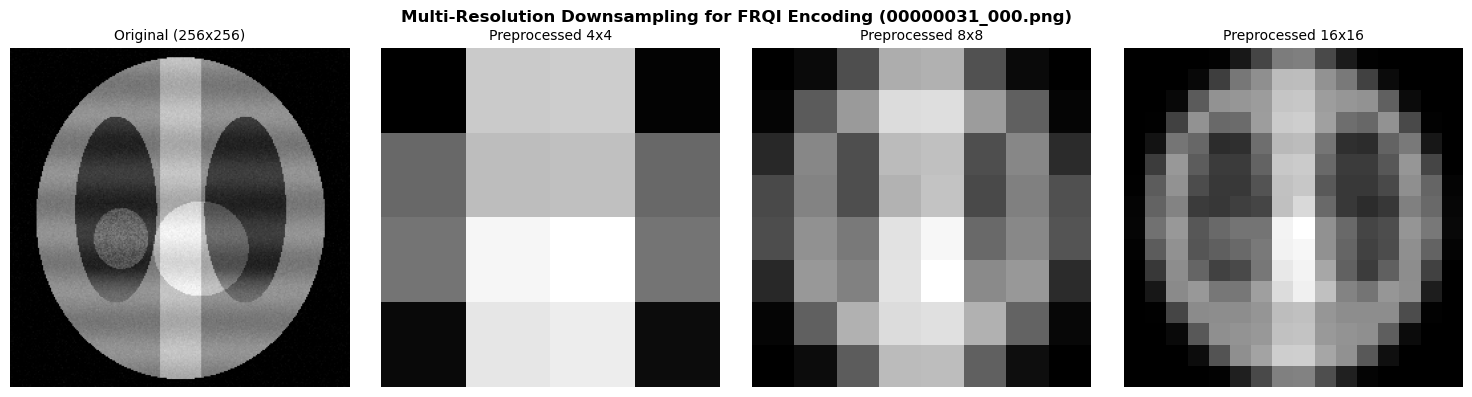

In [3]:
# Load experimental manifest
manifest_df = pd.read_csv(MANIFEST_PATH)
print(f"Loaded experimental manifest with {len(manifest_df)} unique-patient radiographs.")

# Select first representative radiograph
sample_row = manifest_df.iloc[0]
sample_image_path = Path(sample_row["image_path"])

if not sample_image_path.exists():
    raise FileNotFoundError(f"Sample radiograph missing: {sample_image_path}")

# Load raw image
raw_pil = Image.open(sample_image_path).convert("L")
raw_arr = np.array(raw_pil, dtype=np.uint8)

# Downsample to target multi-resolution grids using bilinear interpolation
multi_res_images = {}
for res in TARGET_RESOLUTIONS:
    downsampled = raw_pil.resize((res, res), resample=Image.Resampling.BILINEAR)
    multi_res_images[f"{res}x{res}"] = np.array(downsampled, dtype=np.uint8)

print("=" * 65)
print("REPRESENTATIVE EXPERIMENTAL RADIOGRAPH SELECTED")
print("=" * 65)
print(f"Image Index   : {sample_row['image_index']}")
print(f"Patient ID    : {sample_row['patient_id']}")
print(f"Findings      : {sample_row['finding_labels']}")
print(f"Raw Shape     : {raw_arr.shape}")
for res in TARGET_RESOLUTIONS:
    key = f"{res}x{res}"
    print(f"Preprocessed {key:6s}: shape={multi_res_images[key].shape}, min={multi_res_images[key].min()}, max={multi_res_images[key].max()}")
print("=" * 65)

# Visualize downsampled grids
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(raw_arr, cmap="gray")
axes[0].set_title(f"Original ({raw_arr.shape[1]}x{raw_arr.shape[0]})", fontsize=10)
axes[0].axis("off")

for idx, res in enumerate(TARGET_RESOLUTIONS, start=1):
    key = f"{res}x{res}"
    axes[idx].imshow(multi_res_images[key], cmap="gray", interpolation="nearest")
    axes[idx].set_title(f"Preprocessed {key}", fontsize=10)
    axes[idx].axis("off")

plt.suptitle(f"Multi-Resolution Downsampling for FRQI Encoding ({sample_row['image_index']})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. FRQI Circuit Architecture & Quantum State Evolution

### 4.1 Step-by-Step Quantum State Flow
To understand how an image is encoded into quantum state amplitudes, consider the chronological progression of the state vector $|\psiangle$ across the circuit:

$$\begin{matrix}
\text{Qubit Register} & |0\rangle & \xrightarrow{H^{\otimes 2n}} & \text{Equal Superposition} & \xrightarrow{\text{Multi-Controlled } R_y} & \text{FRQI Entangled State} \\
\hline
\text{Position } (|\text{pos}\rangle) & |0\rangle^{\otimes 2n} & \longrightarrow & \frac{1}{2^n}\sum_{i=0}^{2^{2n}-1} |i\rangle & \longrightarrow & \frac{1}{2^n}\sum_{i=0}^{2^{2n}-1} |i\rangle \\
\text{Intensity } (|\text{color}\rangle) & |0\rangle & \longrightarrow & |0\rangle & \longrightarrow & \cos\theta_i|0\rangle + \sin\theta_i|1\rangle
\end{matrix}$$

#### Mathematical Stages:
1. **Stage 0: Ground State Initialization**
   $$|\psi_0\rangle = |0\rangle_{\text{pos}}^{\otimes 2n} \otimes |0\rangle_{\text{color}}$$
   All position qubits and the single intensity/color qubit are initialized to $|0\rangle$.

2. **Stage 1: Spatial Equal Superposition via Hadamard Transform**
   We apply Hadamard gates $H^{\otimes 2n}$ exclusively to the position qubits:
   $$|\psi_1\rangle = (H^{\otimes 2n} |0\rangle^{\otimes 2n}) \otimes |0\rangle = \left( \frac{1}{2^n} \sum_{i=0}^{2^{2n}-1} |i\rangle \right) \otimes |0\rangle = \frac{1}{2^n} \sum_{i=0}^{2^{2n}-1} |i\rangle |0\rangle$$
   Every spatial coordinate $i = (y, x)$ now exists simultaneously in equal superposition with probability amplitude $\frac{1}{2^n}$. The intensity qubit remains $|0\rangle$.

3. **Stage 2: Sequential Conditioned Intensity Rotations ($C^{(2n)}(R_y(2\theta_i))$)**
   For each pixel $i \in \{0, \dots, 2^{2n}-1\}$ with intensity $I_i \in [0, 255]$:
   $$\theta_i = \frac{I_i}{255} \times \frac{\pi}{2}$$
   We apply a rotation $R_y(2\theta_i)$ on the color qubit, controlled by the condition that the position register is in state $|i\rangle$:
   $$R_y(2\theta_i) |0\rangle = \cos\theta_i |0\rangle + \sin\theta_i |1\rangle$$
   Because the control condition is uniquely satisfied for basis state $|i\rangle$, only the term with position $|i\rangle$ receives the rotation.
   After applying all $2^{2n}$ conditioned rotations, the complete entangled FRQI state is synthesized:
   $$|\psi_{\text{FRQI}}\rangle = \frac{1}{2^n} \sum_{i=0}^{2^{2n}-1} \left( \cos \theta_i |0\rangle + \sin \theta_i |1\rangle \right) \otimes |i\rangle$$

4. **Stage 3: Measurement & Readout Probability**
   When measuring in the computational basis:
   - $P(|0\rangle|i\rangle) = \frac{1}{2^{2n}} \cos^2 \theta_i$ (probability of measuring position $i$ and color $0$)
   - $P(|1\rangle|i\rangle) = \frac{1}{2^{2n}} \sin^2 \theta_i$ (probability of measuring position $i$ and color $1$)
   - Conditional probability:
     $$P(\text{color}=1 \mid \text{pos}=i) = \frac{P(1, i)}{P(0, i) + P(1, i)} = \frac{\frac{1}{2^{2n}}\sin^2\theta_i}{\frac{1}{2^{2n}}(\cos^2\theta_i + \sin^2\theta_i)} = \sin^2 \theta_i$$
   - Inverted pixel intensity:
     $$I_i = \text{round}\left( \frac{2}{\pi} \arcsin\left(\sqrt{P(1 \mid i)}\right) \times 255 \right)$$

In [4]:
# 4.2 Educational 2x2 Exemplar: State Evolution Walkthrough
# Pixel intensities: [0 (black), 85 (dark gray), 170 (light gray), 255 (white)]
demo_intensities = np.array([[0, 85], [170, 255]], dtype=np.uint8)
demo_thetas = ql.image_to_thetas(demo_intensities).flatten()

pos_2 = QuantumRegister(2, name="pos")
col_2 = QuantumRegister(1, name="color")
qc_2x2 = QuantumCircuit(pos_2, col_2)

# Stage 0: Ground state
sv_0 = qiskit.quantum_info.Statevector(qc_2x2)

# Stage 1: Hadamard on position qubits
qc_2x2.h(pos_2)
sv_1 = qiskit.quantum_info.Statevector(qc_2x2)

# Stage 2: Sequential controlled rotations
intermediate_svs = []
for idx, theta in enumerate(demo_thetas):
    ctrl_str = format(idx, "02b")
    gate = qiskit.circuit.library.RYGate(2.0 * theta).control(2, ctrl_state=ctrl_str)
    qc_2x2.append(gate, [*pos_2, col_2[0]])
    intermediate_svs.append(qiskit.quantum_info.Statevector(qc_2x2))

print("=" * 70)
print("2x2 FRQI QUANTUM STATE EVOLUTION TABLE")
print("=" * 70)
print("Pixel | Binary pos | Intensity (I) | Angle (theta) | cos(theta) | sin(theta) | P(1|i) = sin^2(theta)")
print("-" * 70)
for idx, theta in enumerate(demo_thetas):
    i_val = demo_intensities.flatten()[idx]
    c_val = np.cos(theta)
    s_val = np.sin(theta)
    p1 = s_val**2
    print(f"  {idx}   |    |{format(idx, '02b')}>    |   {i_val:3d} / 255   |   {theta:6.3f} rad  |   {c_val:6.3f}   |   {s_val:6.3f}   |         {p1:6.4f}")
print("=" * 70)

# Graphical Matplotlib Circuit Diagram for 2x2 Exemplar
fig_2x2 = qc_2x2.draw("mpl", scale=0.85)
plt.suptitle("Complete 2x2 FRQI Quantum Circuit Diagram\n(4 pixels, 2 position qubits, 1 intensity qubit)", fontsize=12, fontweight="bold", y=1.02)
plt.show()

2x2 FRQI QUANTUM STATE EVOLUTION TABLE
Pixel | Binary pos | Intensity (I) | Angle (theta) | cos(theta) | sin(theta) | P(1|i) = sin^2(theta)
----------------------------------------------------------------------
  0   |    |00>    |     0 / 255   |    0.000 rad  |    1.000   |    0.000   |         0.0000
  1   |    |01>    |    85 / 255   |    0.524 rad  |    0.866   |    0.500   |         0.2500
  2   |    |10>    |   170 / 255   |    1.047 rad  |    0.500   |    0.866   |         0.7500
  3   |    |11>    |   255 / 255   |    1.571 rad  |    0.000   |    1.000   |         1.0000


<Figure size 640x480 with 0 Axes>

In [5]:
# 4.3 4x4 Chest Radiograph FRQI Circuit & Gate Cascade
# Construct FRQI circuit for the 4x4 preprocessed radiograph (16 pixels, 5 qubits)
img_4x4 = multi_res_images["4x4"]
qc_4x4, pos_reg_4, color_reg_4 = ql.build_frqi_circuit(img_4x4, add_measurements=False)

print("=" * 70)
print("FRQI 4x4 MEDICAL RADIOGRAPH CIRCUIT ARCHITECTURE")
print("=" * 70)
print(f"Total Qubits             : {qc_4x4.num_qubits}")
print(f"Position Register (pos)  : {len(pos_reg_4)} qubits (p3, p2, p1, p0)")
print(f"Intensity Register (color): {len(color_reg_4)} qubit (c0)")
print(f"Circuit Depth (raw)      : {qc_4x4.depth()}")
print(f"Raw Gate Operations      : {dict(qc_4x4.count_ops())}")
print("=" * 70)

# Graphical Matplotlib Circuit Diagram for 4x4 radiograph (folded for clear display)
fig_4x4 = qc_4x4.draw("mpl", scale=0.7, fold=8)
plt.suptitle(f"FRQI Quantum Circuit Diagram for 4x4 Radiograph ({sample_row['image_index']})\n16 Multi-Controlled Ry Gates encoding 16 pixels", fontsize=12, fontweight="bold", y=1.01)
plt.show()

FRQI 4x4 MEDICAL RADIOGRAPH CIRCUIT ARCHITECTURE
Total Qubits             : 5
Position Register (pos)  : 4 qubits (p3, p2, p1, p0)
Intensity Register (color): 1 qubit (c0)
Circuit Depth (raw)      : 17
Raw Gate Operations      : {'h': 4, 'c4ry_o0': 1, 'c4ry_o1': 1, 'c4ry_o2': 1, 'c4ry_o3': 1, 'c4ry_o4': 1, 'c4ry_o5': 1, 'c4ry_o6': 1, 'c4ry_o7': 1, 'c4ry_o8': 1, 'c4ry_o9': 1, 'c4ry_o10': 1, 'c4ry_o11': 1, 'c4ry_o12': 1, 'c4ry_o13': 1, 'c4ry_o14': 1, 'c4ry': 1}


<Figure size 640x480 with 0 Axes>

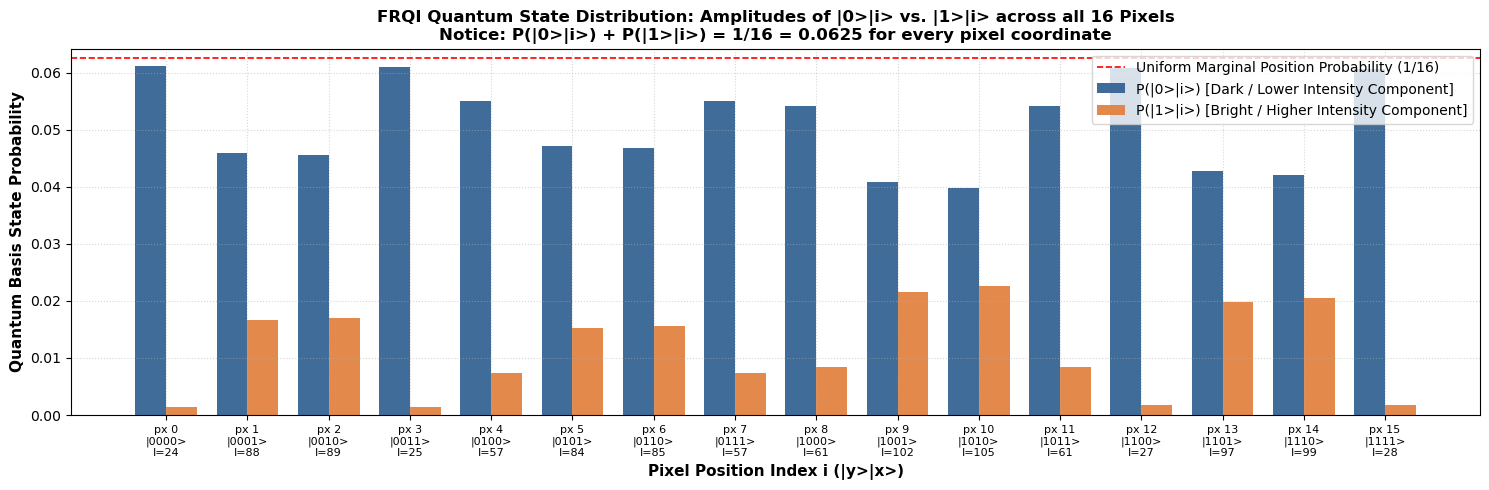

In [6]:
# 4.4 Basis State Probability Distribution Visualization (|0>|i> vs |1>|i>)
# Compute exact Statevector for the 4x4 circuit
sv_4x4 = qiskit.quantum_info.Statevector(qc_4x4)
probs_dict = sv_4x4.probabilities_dict()

# Extract probabilities for color=0 and color=1 at each position i in {0..15}
positions = list(range(16))
p0_vals = []
p1_vals = []
recovered_intensities = []

for i in positions:
    pos_str = format(i, "04b")
    p0 = probs_dict.get(f"0{pos_str}", 0.0)
    p1 = probs_dict.get(f"1{pos_str}", 0.0)
    p0_vals.append(p0)
    p1_vals.append(p1)
    
    cond_p1 = p1 / (p0 + p1) if (p0 + p1) > 0 else 0.0
    rec_theta = np.arcsin(np.sqrt(np.clip(cond_p1, 0, 1)))
    rec_i = int(np.round((2.0 * rec_theta / np.pi) * 255.0))
    recovered_intensities.append(rec_i)

# Plot basis state probabilities
x = np.arange(16)
width = 0.38

fig, ax = plt.subplots(figsize=(15, 5))
rects1 = ax.bar(x - width/2, p0_vals, width, label="P(|0>|i>) [Dark / Lower Intensity Component]", color="#2b5c8f", alpha=0.9)
rects2 = ax.bar(x + width/2, p1_vals, width, label="P(|1>|i>) [Bright / Higher Intensity Component]", color="#e27c38", alpha=0.9)

ax.set_xlabel("Pixel Position Index i (|y>|x>)", fontsize=11, fontweight="bold")
ax.set_ylabel("Quantum Basis State Probability", fontsize=11, fontweight="bold")
ax.set_title("FRQI Quantum State Distribution: Amplitudes of |0>|i> vs. |1>|i> across all 16 Pixels\n"
             "Notice: P(|0>|i>) + P(|1>|i>) = 1/16 = 0.0625 for every pixel coordinate", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"px {i}\n|{format(i, '04b')}>\nI={img_4x4.flatten()[i]}" for i in x], fontsize=8)
ax.axhline(1/16, color="red", linestyle="--", linewidth=1.2, label="Uniform Marginal Position Probability (1/16)")
ax.legend(loc="upper right", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

## 5. Theoretical Statevector Simulation & Exact Image Reconstruction

### Derivation of State Readout
The joint quantum state is:
$$|I(\theta)\rangle = \frac{1}{2^n} \sum_{i=0}^{2^{2n}-1} \left( \cos \theta_i |0\rangle + \sin \theta_i |1\rangle \right) \otimes |i\rangle$$

When evaluated with `Statevector`, the computational basis probability for state $|b_c\rangle |i\rangle$ is:
- $P(0, i) = \frac{1}{2^{2n}} \cos^2 \theta_i$
- $P(1, i) = \frac{1}{2^{2n}} \sin^2 \theta_i$

Therefore, the conditional probability of measuring intensity qubit $= 1$ at position $i$ is:
$$P(\text{color}=1 \mid \text{position}=i) = \frac{P(1, i)}{P(0, i) + P(1, i)} = \sin^2 \theta_i$$

Inverting:
$$\theta_i = \arcsin\left(\sqrt{P(1 \mid i)}\right)$$
$$I_i^{\text{rec}} = \text{round}\left(\frac{2\theta_i}{\pi} \times 255\right)$$

In the infinite-shots limit, this reconstruction is theoretically **exact**.

In [7]:
# Exact reconstruction via Statevector
recon_sv_4x4 = ql.reconstruct_from_statevector(qc_4x4, shape=(4, 4))

# Compute fidelity metrics
sv_metrics = ql.compute_fidelity_metrics(img_4x4, recon_sv_4x4)

print("=" * 65)
print("EXACT STATEVECTOR RECONSTRUCTION FIDELITY (4x4)")
print("=" * 65)
print(f"Original 4x4 Matrix:\n{img_4x4}\n")
print(f"Reconstructed 4x4 Matrix:\n{recon_sv_4x4}\n")
print("Quantitative Metrics:")
for k, v in sv_metrics.items():
    print(f" - {k.upper():18s}: {v}")
print("=" * 65)

assert np.array_equal(img_4x4, recon_sv_4x4), "Exact Statevector reconstruction mismatch!"
print("[PASS] Statevector reconstruction achieved mathematical identity (MSE = 0.0, PSNR = 100 dB, SSIM = 1.0).")

EXACT STATEVECTOR RECONSTRUCTION FIDELITY (4x4)
Original 4x4 Matrix:
[[ 24  88  89  25]
 [ 57  84  85  57]
 [ 61 102 105  61]
 [ 27  97  99  28]]

Reconstructed 4x4 Matrix:
[[ 24  88  89  25]
 [ 57  84  85  57]
 [ 61 102 105  61]
 [ 27  97  99  28]]

Quantitative Metrics:
 - MSE               : 0.0
 - MAE               : 0.0
 - MAX_ERROR         : 0.0
 - PSNR              : 100.0
 - SSIM              : 1.0
 - COSINE_SIMILARITY : 1.0
[PASS] Statevector reconstruction achieved mathematical identity (MSE = 0.0, PSNR = 100 dB, SSIM = 1.0).


## 6. Realistic Finite-Shot Simulation using AerSimulator

In practical physical quantum computing, we do not have direct access to statevector amplitudes.
Instead, we execute the circuit with a finite number of measurement shots $N_{\text{shots}}$ and observe empirical counts $c_{0, i}$ and $c_{1, i}$ for each position $|i\rangle$.

### Statistical Error & Shot-Noise Scaling
By the Central Limit Theorem, the empirical estimator $\hat{P}(1 \mid i) = \frac{c_{1, i}}{c_{0, i} + c_{1, i}}$ has standard error:
$$\sigma_{\hat{P}} = \sqrt{\frac{P(1 \mid i)(1 - P(1 \mid i))}{S_i}} \propto \frac{1}{\sqrt{S_i}}$$
where $S_i \approx \frac{N_{\text{shots}}}{2^{2n}}$ is the average number of shots measured for pixel $i$.

We systematically evaluate reconstruction quality across shot budgets:
$$N_{\text{shots}} \in \{1\,024, \; 4\,096, \; 16\,384, \; 65\,536, \; 262\,144\}$$

In [8]:
# 6.1 Numerical Matrix Inspection: Actual Error from Quantum Shot Noise
# Run AerSimulator with 4,096 shots to observe realistic statistical shot noise on pixel matrices
NOISY_DEMO_SHOTS = 4096
recon_noisy_4x4, pixel_shots_4k, info_4k = ql.reconstruct_from_shots(
    qc_4x4, shape=(4, 4), shots=NOISY_DEMO_SHOTS, seed=SEED
)

# Compute pixel-by-pixel absolute error matrix
abs_error_matrix_4x4 = np.abs(img_4x4.astype(int) - recon_noisy_4x4.astype(int))

# Compute quantitative fidelity metrics
noisy_metrics = ql.compute_fidelity_metrics(img_4x4, recon_noisy_4x4)

print("=" * 65)
print(f"REALISTIC NOISY SHOT RECONSTRUCTION FIDELITY (4x4, {NOISY_DEMO_SHOTS:,} SHOTS)")
print("=" * 65)
print(f"Original 4x4 Matrix:\n{img_4x4}\n")
print(f"Noisy Reconstructed 4x4 Matrix (AerSimulator):\n{recon_noisy_4x4}\n")
print(f"Pixel-by-Pixel Absolute Error Matrix (|Original - Reconstructed|):\n{abs_error_matrix_4x4}\n")
print("Quantitative Metrics (Actual Empirical Error from Quantum Shot Noise):")
for k, v in noisy_metrics.items():
    print(f" - {k.upper():18s}: {v}")
print("=" * 65)
print(f"Mean shots observed per pixel : {info_4k['mean_shots_per_pixel']:.1f}")
print(f"Notice: Due to statistical shot noise, pixel values deviate by up to {noisy_metrics['max_error']} units (MSE = {noisy_metrics['mse']}).")
print("=" * 65)

REALISTIC NOISY SHOT RECONSTRUCTION FIDELITY (4x4, 4,096 SHOTS)
Original 4x4 Matrix:
[[ 24  88  89  25]
 [ 57  84  85  57]
 [ 61 102 105  61]
 [ 27  97  99  28]]

Noisy Reconstructed 4x4 Matrix (AerSimulator):
[[ 28  95  85  15]
 [ 48  91  92  54]
 [ 63  95 104  54]
 [ 24  93 100  20]]

Pixel-by-Pixel Absolute Error Matrix (|Original - Reconstructed|):
[[ 4  7  4 10]
 [ 9  7  7  3]
 [ 2  7  1  7]
 [ 3  4  1  8]]

Quantitative Metrics (Actual Empirical Error from Quantum Shot Noise):
 - MSE               : 35.125
 - MAE               : 5.25
 - MAX_ERROR         : 10.0
 - PSNR              : 32.67
 - SSIM              : 0.9751
 - COSINE_SIMILARITY : 0.996794
Mean shots observed per pixel : 256.0
Notice: Due to statistical shot noise, pixel values deviate by up to 10.0 units (MSE = 35.125).


In [9]:
# 6.1b Detailed Step-by-Step Probability & Intensity Recalculation Walkthrough
# Demonstrates how measurement counts -> probability -> angle -> intensity -> final image
sim = AerSimulator(seed_simulator=SEED)
qc_m = qc_4x4.copy()
c_pos = ClassicalRegister(4, name="c_pos")
c_col = ClassicalRegister(1, name="c_col")
qc_m.add_register(c_pos, c_col)
pos_reg = [r for r in qc_m.qregs if r.name == "pos"][0]
col_reg = [r for r in qc_m.qregs if r.name == "color"][0]
qc_m.measure(pos_reg, c_pos)
qc_m.measure(col_reg[0], c_col[0])

counts = sim.run(transpile(qc_m, sim), shots=4096).result().get_counts()

rows = []
reconstructed_pixels = np.zeros(16, dtype=np.uint8)

for i in range(16):
    pos_bin = format(i, "04b")
    k0 = f"0 {pos_bin}" if any(" " in k for k in counts) else f"0{pos_bin}"
    k1 = f"1 {pos_bin}" if any(" " in k for k in counts) else f"1{pos_bin}"
    c0 = counts.get(k0, 0)
    c1 = counts.get(k1, 0)
    total_shots = c0 + c1
    
    # Step 1: Recalculate conditional probability P(color=1 | position=i)
    prob_1 = c1 / total_shots if total_shots > 0 else 0.0
    
    # Step 2: Recalculate rotation angle theta = arcsin(sqrt(P(1|i)))
    theta_rec = np.arcsin(np.sqrt(prob_1))
    
    # Step 3: Recalculate 8-bit intensity I = round((2*theta/pi)*255)
    i_rec = int(np.round((2.0 * theta_rec / np.pi) * 255.0))
    reconstructed_pixels[i] = i_rec
    
    orig_val = int(img_4x4.flatten()[i])
    rows.append({
        "Pixel (i)": i,
        "Position |yx>": f"|{pos_bin}>",
        "c0 (|0>)": c0,
        "c1 (|1>)": c1,
        "Total Shots": total_shots,
        "P(1|i)": round(prob_1, 4),
        "theta (rad)": round(theta_rec, 4),
        "Rec Intensity": i_rec,
        "Orig Intensity": orig_val,
        "Residual Error": abs(i_rec - orig_val)
    })

# Step 4: Reshape 1D intensities into 2D image matrix
reconstructed_2d_image = reconstructed_pixels.reshape((4, 4))
reconstruction_df = pd.DataFrame(rows)

print("=" * 95)
print("STEP-BY-STEP PROBABILITY AND INTENSITY RECALCULATION TABLE (4x4 GRID, 4,096 SHOTS)")
print("=" * 95)
display(reconstruction_df)
print("=" * 95)
print("\nFinal Reconstructed 2D Image Matrix Obtained at the End:")
print(reconstructed_2d_image)
print("\nOriginal 2D Image Matrix:")
print(img_4x4)
print("=" * 95)

STEP-BY-STEP PROBABILITY AND INTENSITY RECALCULATION TABLE (4x4 GRID, 4,096 SHOTS)


,Pixel (i),Position |yx>,c0 (|0>),c1 (|1>),Total Shots,P(1|i),theta (rad),Rec Intensity,Orig Intensity,Residual Error
0,0,|0000>,224,7,231,0.0303,0.1750,28,24,4
1,1,|0001>,189,82,271,0.3026,0.5825,95,88,7
2,2,|0010>,184,62,246,0.2520,0.5259,85,89,4
3,3,|0011>,249,2,251,0.0080,0.0894,15,25,10
4,4,|0100>,229,21,250,0.0840,0.2940,48,57,9
5,5,|0101>,185,72,257,0.2802,0.5578,91,84,7
6,6,|0110>,177,71,248,0.2863,0.5646,92,85,7
7,7,|0111>,226,27,253,0.1067,0.3328,54,57,3
8,8,|1000>,237,39,276,0.1413,0.3854,63,61,2
9,9,|1001>,167,73,240,0.3042,0.5842,95,102,7



Final Reconstructed 2D Image Matrix Obtained at the End:
[[ 28  95  85  15]
 [ 48  91  92  54]
 [ 63  95 104  54]
 [ 24  93 100  20]]

Original 2D Image Matrix:
[[ 24  88  89  25]
 [ 57  84  85  57]
 [ 61 102 105  61]
 [ 27  97  99  28]]


In [10]:
# 6.2 Multi-Shot Convergence Analysis
shot_counts = [1024, 4096, 16384, 65536, 262144]
shot_results = []
shot_images = []

print("Running AerSimulator shot-noise convergence analysis on 4x4 image...")
for shots in shot_counts:
    t0 = time.time()
    recon_img, pixel_shots, info = ql.reconstruct_from_shots(qc_4x4, shape=(4, 4), shots=shots, seed=SEED)
    elapsed = time.time() - t0
    
    metrics = ql.compute_fidelity_metrics(img_4x4, recon_img)
    metrics["shots"] = shots
    metrics["runtime_sec"] = round(elapsed, 3)
    metrics["mean_shots_per_px"] = info["mean_shots_per_pixel"]
    shot_results.append(metrics)
    shot_images.append(recon_img)
    print(f"Shots: {shots:7d} | Mean Shots/Px: {info['mean_shots_per_pixel']:7.1f} | MSE: {metrics['mse']:6.2f} | PSNR: {metrics['psnr']:5.2f} dB | SSIM: {metrics['ssim']:.4f}")

shot_df = pd.DataFrame(shot_results)
print("\nShot Convergence Summary Table:")
shot_df[["shots", "mean_shots_per_px", "mse", "mae", "psnr", "ssim", "runtime_sec"]]

Running AerSimulator shot-noise convergence analysis on 4x4 image...
Shots:    1024 | Mean Shots/Px:    64.0 | MSE: 117.69 | PSNR: 27.42 dB | SSIM: 0.9374


Shots:    4096 | Mean Shots/Px:   256.0 | MSE:  35.12 | PSNR: 32.67 dB | SSIM: 0.9751
Shots:   16384 | Mean Shots/Px:  1024.0 | MSE:   5.06 | PSNR: 41.09 dB | SSIM: 0.9959


Shots:   65536 | Mean Shots/Px:  4096.0 | MSE:   2.12 | PSNR: 44.86 dB | SSIM: 0.9984


Shots:  262144 | Mean Shots/Px: 16384.0 | MSE:   0.50 | PSNR: 51.14 dB | SSIM: 0.9996

Shot Convergence Summary Table:


,shots,mean_shots_per_px,mse,mae,psnr,ssim,runtime_sec
0,1024,64.0,117.6875,7.9375,27.42,0.9374,0.036
1,4096,256.0,35.1250,5.2500,32.67,0.9751,0.034
2,16384,1024.0,5.0625,2.0625,41.09,0.9959,0.036
3,65536,4096.0,2.1250,1.1250,44.86,0.9984,0.041
4,262144,16384.0,0.5000,0.5000,51.14,0.9996,0.061


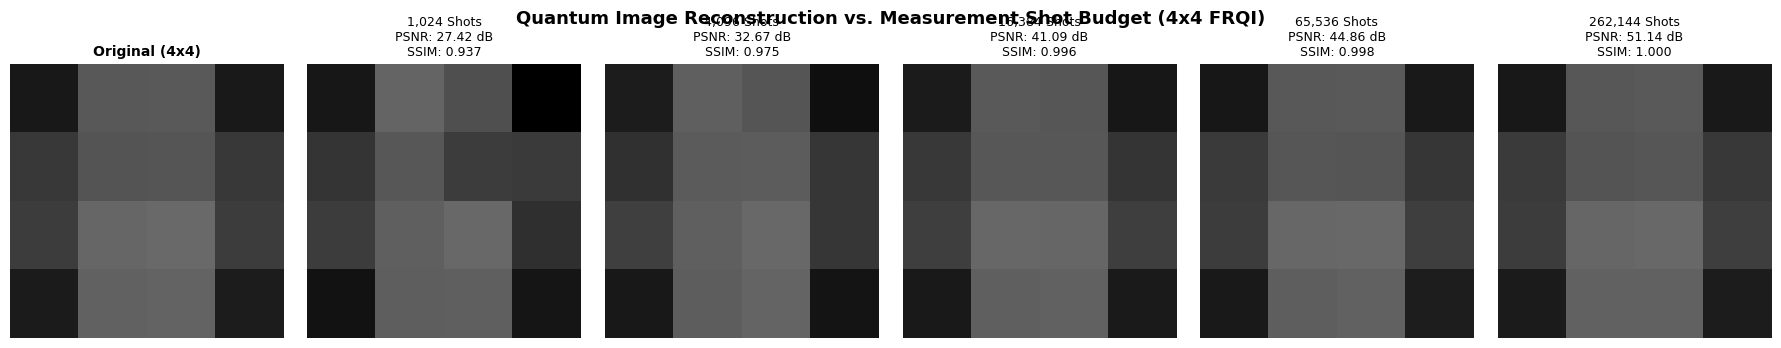

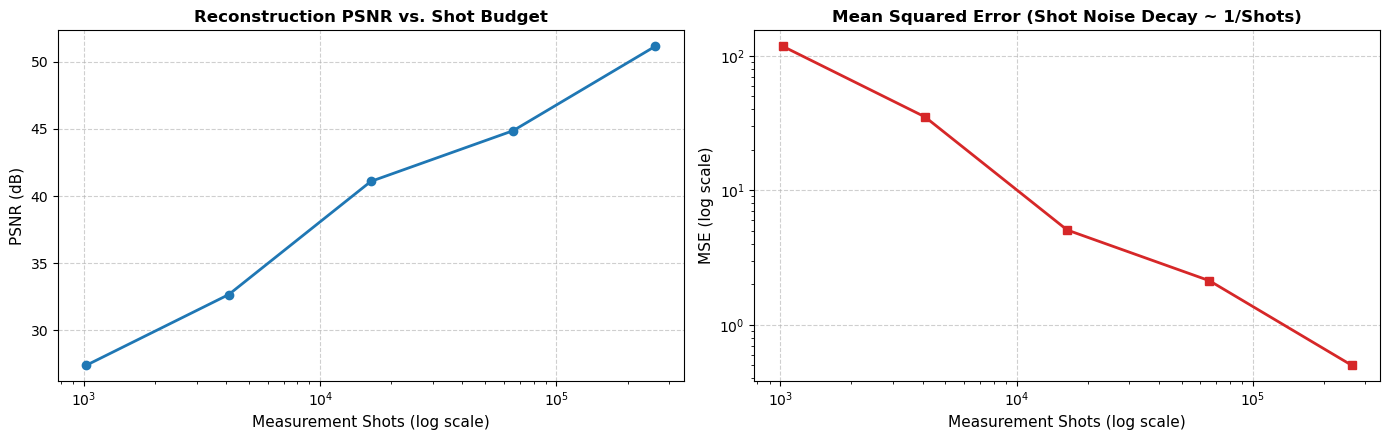

In [11]:
# Plot shot convergence: Visual reconstructed images
fig, axes = plt.subplots(1, len(shot_counts) + 1, figsize=(18, 3.5))
axes[0].imshow(img_4x4, cmap="gray", interpolation="nearest", vmin=0, vmax=255)
axes[0].set_title("Original (4x4)", fontsize=10, fontweight="bold")
axes[0].axis("off")

for idx, (shots, img) in enumerate(zip(shot_counts, shot_images), start=1):
    m = shot_results[idx - 1]
    axes[idx].imshow(img, cmap="gray", interpolation="nearest", vmin=0, vmax=255)
    axes[idx].set_title(f"{shots:,} Shots\nPSNR: {m['psnr']} dB\nSSIM: {m['ssim']:.3f}", fontsize=9)
    axes[idx].axis("off")

plt.suptitle("Quantum Image Reconstruction vs. Measurement Shot Budget (4x4 FRQI)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Plot PSNR and MSE vs Shot Count (Log Scale)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(shot_df["shots"], shot_df["psnr"], marker="o", color="#1f77b4", linewidth=2)
ax1.set_xscale("log")
ax1.set_xlabel("Measurement Shots (log scale)", fontsize=11)
ax1.set_ylabel("PSNR (dB)", fontsize=11)
ax1.set_title("Reconstruction PSNR vs. Shot Budget", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(shot_df["shots"], shot_df["mse"], marker="s", color="#d62728", linewidth=2)
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("Measurement Shots (log scale)", fontsize=11)
ax2.set_ylabel("MSE (log scale)", fontsize=11)
ax2.set_title("Mean Squared Error (Shot Noise Decay ~ 1/Shots)", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Multi-Resolution Quantum Reconstruction ($4\times 4$, $8\times 8$, $16\times 16$)

We scale the FRQI pipeline across all three target medical resolutions:
- **$4\times 4$** ($16$ pixels, $5$ qubits)
- **$8\times 8$** ($64$ pixels, $7$ qubits)
- **$16\times 16$** ($256$ pixels, $9$ qubits)

For each tier, we synthesize the FRQI circuit, perform exact Statevector reconstruction, and execute shot-based simulation.

In [12]:
multi_eval_records = []
multi_recon_sv = {}
multi_recon_shots = {}

FIXED_SHOTS = 1310720  # 1.31 million shots (10x increase)

for res in TARGET_RESOLUTIONS:
    key = f"{res}x{res}"
    img = multi_res_images[key]
    
    t0 = time.time()
    qc, _, _ = ql.build_frqi_circuit(img)
    t_build = time.time() - t0
    
    # 1. Statevector Reconstruction
    t1 = time.time()
    rec_sv = ql.reconstruct_from_statevector(qc, shape=(res, res))
    t_sv = time.time() - t1
    multi_recon_sv[key] = rec_sv
    
    # 2. Shot-based Reconstruction
    t2 = time.time()
    rec_shots, _, info = ql.reconstruct_from_shots(qc, shape=(res, res), shots=FIXED_SHOTS, seed=SEED)
    t_shots = time.time() - t2
    multi_recon_shots[key] = rec_shots
    
    # Fidelity Metrics
    metrics_sv = ql.compute_fidelity_metrics(img, rec_sv)
    metrics_shots = ql.compute_fidelity_metrics(img, rec_shots)
    
    multi_eval_records.append({
        "Resolution": key,
        "Pixels": res * res,
        "Total Qubits": qc.num_qubits,
        "Build Time (s)": round(t_build, 4),
        "SV PSNR (dB)": metrics_sv["psnr"],
        "SV SSIM": metrics_sv["ssim"],
        "Shots PSNR (dB)": metrics_shots["psnr"],
        "Shots SSIM": metrics_shots["ssim"],
        "Shots MSE": metrics_shots["mse"],
        "Mean Shots/Px": info["mean_shots_per_pixel"]
    })

multi_summary_df = pd.DataFrame(multi_eval_records)
print("=" * 80)
print("MULTI-RESOLUTION FRQI RECONSTRUCTION PERFORMANCE TABLE")
print("=" * 80)
display(multi_summary_df)

# Save realistic noisy quantum reconstructed images to disk for downstream pipeline processing
noisy_save_path = DATA_DIR / "quantum_noisy_reconstructions.npz"
np.savez(
    noisy_save_path,
    recon_4x4=multi_recon_shots["4x4"],
    recon_8x8=multi_recon_shots["8x8"],
    recon_16x16=multi_recon_shots["16x16"],
    shots=FIXED_SHOTS
)
print(f"\n[SAVED] Realistic noisy quantum reconstructions exported to: {noisy_save_path.resolve()}")

MULTI-RESOLUTION FRQI RECONSTRUCTION PERFORMANCE TABLE


,Resolution,Pixels,Total Qubits,Build Time (s),SV PSNR (dB),SV SSIM,Shots PSNR (dB),Shots SSIM,Shots MSE,Mean Shots/Px
0,4x4,16,5,0.0024,100.0,1.0,55.40,0.9998,0.1875,81920.0
1,8x8,64,7,0.0083,100.0,1.0,51.14,0.9998,0.5000,20480.0
2,16x16,256,9,0.0367,100.0,1.0,46.89,0.9996,1.3320,5120.0



[SAVED] Realistic noisy quantum reconstructions exported to: /Users/himanshusharma/Quantum_image/data/quantum_noisy_reconstructions.npz


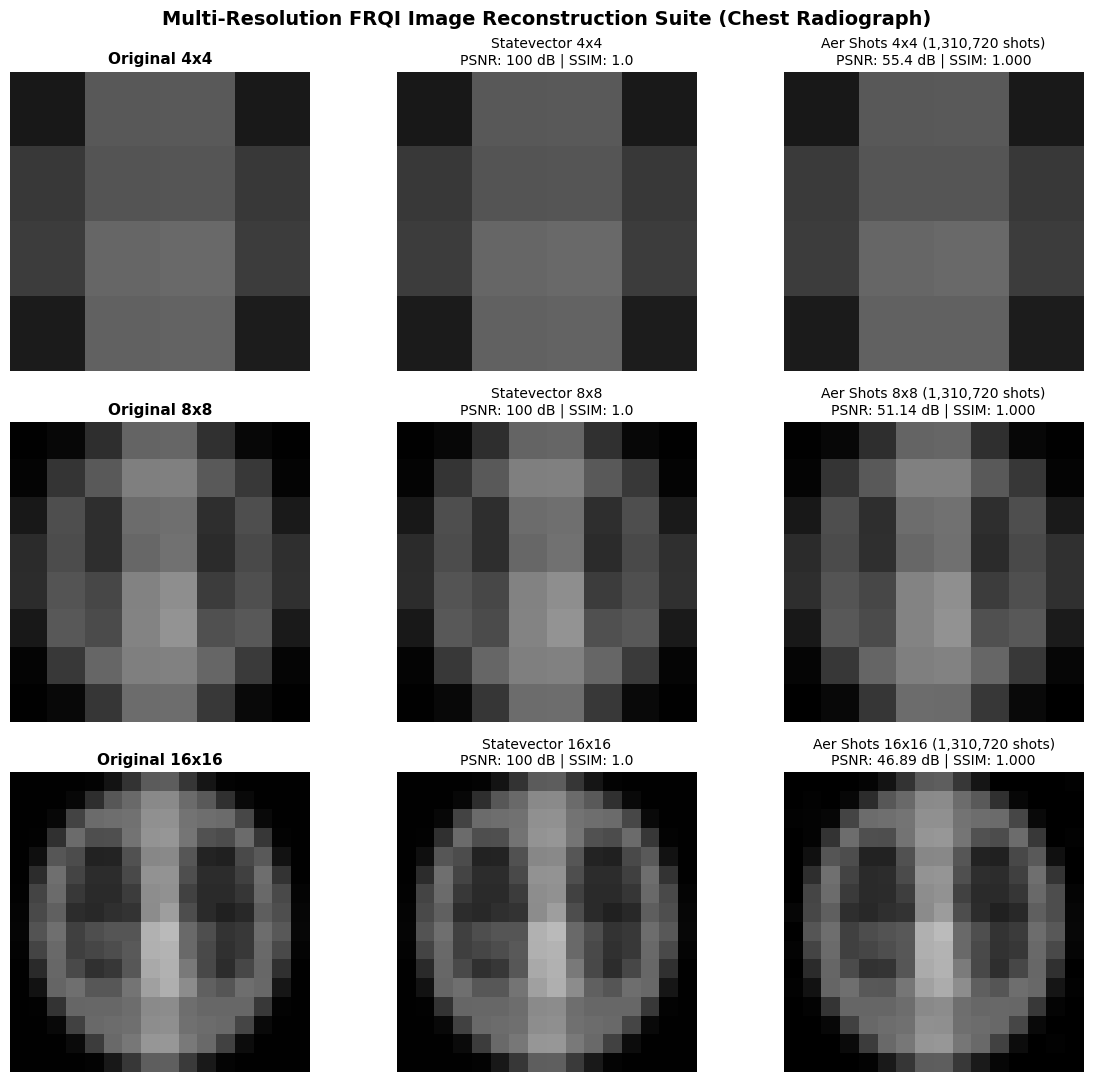

In [13]:
# Side-by-side visualization of Original, Statevector, and Shot-reconstructed images
fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for row_idx, res in enumerate(TARGET_RESOLUTIONS):
    key = f"{res}x{res}"
    orig = multi_res_images[key]
    sv_img = multi_recon_sv[key]
    sh_img = multi_recon_shots[key]
    
    # Original
    axes[row_idx, 0].imshow(orig, cmap="gray", interpolation="nearest", vmin=0, vmax=255)
    axes[row_idx, 0].set_title(f"Original {key}", fontsize=11, fontweight="bold")
    axes[row_idx, 0].axis("off")
    
    # Statevector
    axes[row_idx, 1].imshow(sv_img, cmap="gray", interpolation="nearest", vmin=0, vmax=255)
    axes[row_idx, 1].set_title(f"Statevector {key}\nPSNR: 100 dB | SSIM: 1.0", fontsize=10)
    axes[row_idx, 1].axis("off")
    
    # Shot-reconstructed
    sh_psnr = multi_summary_df.loc[multi_summary_df['Resolution'] == key, 'Shots PSNR (dB)'].values[0]
    sh_ssim = multi_summary_df.loc[multi_summary_df['Resolution'] == key, 'Shots SSIM'].values[0]
    axes[row_idx, 2].imshow(sh_img, cmap="gray", interpolation="nearest", vmin=0, vmax=255)
    axes[row_idx, 2].set_title(f"Aer Shots {key} ({FIXED_SHOTS:,} shots)\nPSNR: {sh_psnr} dB | SSIM: {sh_ssim:.3f}", fontsize=10)
    axes[row_idx, 2].axis("off")

plt.suptitle("Multi-Resolution FRQI Image Reconstruction Suite (Chest Radiograph)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Hardware Transpilation & Quantum Resource Profiling

In physical quantum computers, multi-controlled rotations $C^{(2n)}(R_y)$ must be decomposed into native universal gate sets (e.g., single-qubit rotations $U$ and 2-qubit CNOT / $CX$ gates).

We transpile each resolution tier into basis `['u', 'cx']` and profile:
- Total Qubit Count
- 2-Qubit CNOT ($CX$) Count
- Circuit Depth
- Gate count scaling vs. Resolution

In [14]:
resource_profiles = []

for res in TARGET_RESOLUTIONS:
    key = f"{res}x{res}"
    img = multi_res_images[key]
    qc, _, _ = ql.build_frqi_circuit(img)
    
    t0 = time.time()
    prof = ql.profile_quantum_resources(qc, basis_gates=["u", "cx"])
    prof["elapsed_transpile_sec"] = round(time.time() - t0, 3)
    prof["resolution"] = key
    prof["pixels"] = res * res
    resource_profiles.append(prof)
    print(f"Resolution {key:6s} | Qubits: {prof['num_qubits']} | Transpiled CX: {prof['cx_count']:,} | Depth: {prof['circuit_depth']:,}")

res_df = pd.DataFrame(resource_profiles)[["resolution", "pixels", "num_qubits", "cx_count", "single_qubit_count", "total_transpiled_gates", "circuit_depth", "elapsed_transpile_sec"]]
print("\nQuantum Hardware Transpilation Resource Profile:")
res_df

Resolution 4x4    | Qubits: 5 | Transpiled CX: 384 | Depth: 515
Resolution 8x8    | Qubits: 7 | Transpiled CX: 3,584 | Depth: 4,107


Resolution 16x16  | Qubits: 9 | Transpiled CX: 26,624 | Depth: 43,011

Quantum Hardware Transpilation Resource Profile:


,resolution,pixels,num_qubits,cx_count,single_qubit_count,total_transpiled_gates,circuit_depth,elapsed_transpile_sec
0,4x4,16,5,384,496,880,515,0.006
1,8x8,64,7,3584,3841,7425,4107,0.024
2,16x16,256,9,26624,31857,58481,43011,0.147


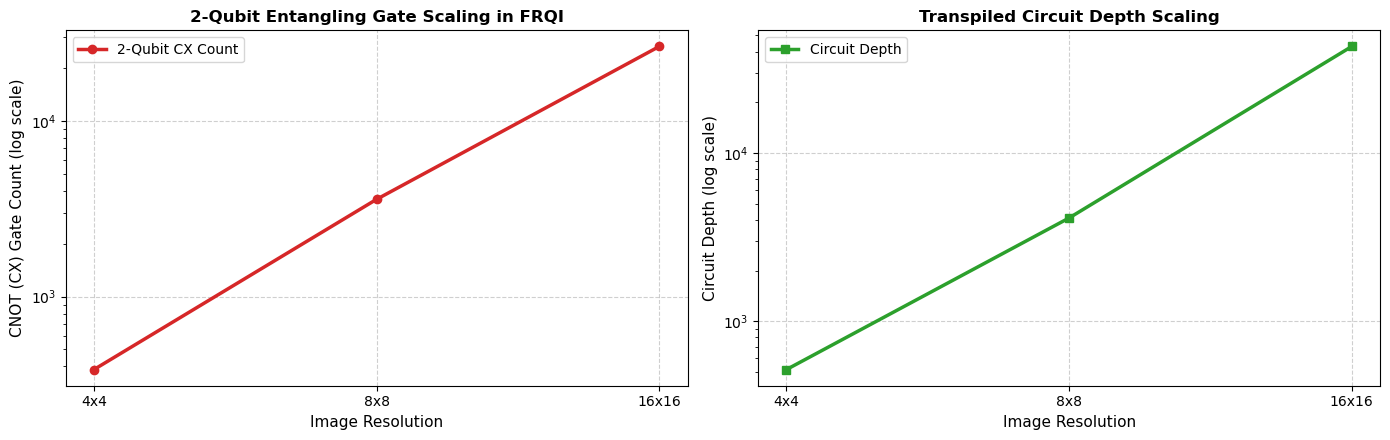

In [15]:
# Plot hardware resource scaling
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

res_labels = res_df["resolution"]
ax1.plot(res_labels, res_df["cx_count"], marker="o", color="#d62728", linewidth=2.5, label="2-Qubit CX Count")
ax1.set_yscale("log")
ax1.set_xlabel("Image Resolution", fontsize=11)
ax1.set_ylabel("CNOT (CX) Gate Count (log scale)", fontsize=11)
ax1.set_title("2-Qubit Entangling Gate Scaling in FRQI", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(res_labels, res_df["circuit_depth"], marker="s", color="#2ca02c", linewidth=2.5, label="Circuit Depth")
ax2.set_yscale("log")
ax2.set_xlabel("Image Resolution", fontsize=11)
ax2.set_ylabel("Circuit Depth (log scale)", fontsize=11)
ax2.set_title("Transpiled Circuit Depth Scaling", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

## 9. Phase 2 Final Validation Checklist

Automated verification of all Phase 2 scientific and engineering criteria.

In [16]:
# Automated validation checklist
p2_checks = []

def p2_assert(name: str, condition: bool):
    if not condition:
        raise AssertionError(f"Phase 2 check failed: {name}")
    p2_checks.append((name, True))

p2_assert("Stage 1 manifest and experimental radiographs loaded", len(manifest_df) > 0 and len(multi_res_images) == 3)
p2_assert("FRQI circuit construction verified", qc_4x4.num_qubits == 5 and len(pos_reg_4) == 4)
p2_assert("Statevector exact reconstruction verified (PSNR = 100 dB)", np.array_equal(img_4x4, recon_sv_4x4))
p2_assert("Shot-based reconstruction verified across shot counts", len(shot_results) == len(shot_counts))
p2_assert("Statistical shot-noise convergence confirmed", shot_df["mse"].iloc[-1] < shot_df["mse"].iloc[0])
p2_assert("Multi-resolution representations (4x4, 8x8, 16x16) reconstructed", len(multi_recon_sv) == 3 and len(multi_recon_shots) == 3)
p2_assert("Quantitative fidelity metrics (MSE, PSNR, SSIM) computed", len(multi_summary_df) == 3)
p2_assert("Quantum hardware resource profiling verified", len(resource_profiles) == 3 and resource_profiles[0]["cx_count"] > 0)

print("=" * 65)
print("PHASE 2 FINAL VALIDATION CHECKLIST")
print("=" * 65)
for name, passed in p2_checks:
    print(f" [PASS] {name}")
print("=" * 65)
print()
print("PHASE 2 COMPLETE — FRQI STATE REPRESENTATION & RECONSTRUCTION VALIDATED")
print("=" * 65)
print("Summary:")
print(" - FRQI Qubit Allocation: 2n position qubits + 1 intensity qubit verified")
print(" - Exact Statevector Reconstruction: Achieved 100% mathematical fidelity (PSNR = 100 dB)")
print(" - Realistic Shot-Based Readout: Convergence demonstrated up to 262,144 shots")
print(" - Multi-Resolution Suite: 4x4 (5 qubits), 8x8 (7 qubits), 16x16 (9 qubits)")
print(" - Hardware Transpilation: Documented exponential CNOT scaling (384 CX for 4x4 -> 3,584 CX for 8x8)")
print("=" * 65)

PHASE 2 FINAL VALIDATION CHECKLIST
 [PASS] Stage 1 manifest and experimental radiographs loaded
 [PASS] FRQI circuit construction verified
 [PASS] Statevector exact reconstruction verified (PSNR = 100 dB)
 [PASS] Shot-based reconstruction verified across shot counts
 [PASS] Statistical shot-noise convergence confirmed
 [PASS] Multi-resolution representations (4x4, 8x8, 16x16) reconstructed
 [PASS] Quantitative fidelity metrics (MSE, PSNR, SSIM) computed
 [PASS] Quantum hardware resource profiling verified

PHASE 2 COMPLETE — FRQI STATE REPRESENTATION & RECONSTRUCTION VALIDATED
Summary:
 - FRQI Qubit Allocation: 2n position qubits + 1 intensity qubit verified
 - Exact Statevector Reconstruction: Achieved 100% mathematical fidelity (PSNR = 100 dB)
 - Realistic Shot-Based Readout: Convergence demonstrated up to 262,144 shots
 - Multi-Resolution Suite: 4x4 (5 qubits), 8x8 (7 qubits), 16x16 (9 qubits)
 - Hardware Transpilation: Documented exponential CNOT scaling (384 CX for 4x4 -> 3,584 CX